In [1]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
%pip install -q fastapi uvicorn pyngrok python-multipart pillow opencv-python-headless

In [5]:
from huggingface_hub import model_info

MODEL_ID = "facebook/sam3"

try:
    info = model_info(MODEL_ID)
    print("Checkpoint accessible:", MODEL_ID)
    print("Model revision:", info.sha)
except Exception as e:
    print("Checkpoint access failed:")
    print(type(e).__name__, str(e))

Checkpoint accessible: facebook/sam3
Model revision: 3c879f39826c281e95690f02c7821c4de09afae7


In [4]:
from huggingface_hub import login

login()

In [6]:
import torch
from transformers import Sam3Model, Sam3Processor

MODEL_ID = "facebook/sam3"
DEVICE = "cuda"

print("Loading SAM3 onto", torch.cuda.get_device_name(0))

processor = Sam3Processor.from_pretrained(MODEL_ID)

model = Sam3Model.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16
).to(DEVICE)

model.eval()

print("\nSAM3 loaded successfully!")
print("Device:", next(model.parameters()).device)
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Loading SAM3 onto Tesla T4


processor_config.json:   0%|          | 0.00/1.71k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

[transformers] `memory_attention_rope_theta` is deprecated and will be removed in v5.0. Use `rope_parameters['rope_theta']` instead.


tokenizer_config.json:   0%|          | 0.00/799 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]


SAM3 loaded successfully!
Device: cuda:0
GPU memory allocated: 1.59 GB


In [7]:
import io
import time
import threading

import cv2
import numpy as np
import torch

from PIL import Image
from fastapi import FastAPI, File, UploadFile
from fastapi.responses import Response

DEVICE = next(model.parameters()).device

print("SAM3 device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Server dependencies imported.")

SAM3 device: cuda:0
GPU: Tesla T4
Server dependencies imported.


In [8]:
FACIAL_ZONES = [
    "forehead",
    "left cheek",
    "right cheek",
    "nose",
    "chin"
]

print("Configured zones:")
for zone in FACIAL_ZONES:
    print("-", zone)

Configured zones:
- forehead
- left cheek
- right cheek
- nose
- chin


In [9]:
def segment_zone(image, zone):
    image = image.convert("RGB")

    inputs = processor(
        images=image,
        text=zone,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(DEVICE) if hasattr(value, "to") else value
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        outputs = model(**inputs)

    results = processor.post_process_instance_segmentation(
        outputs,
        threshold=0.5,
        mask_threshold=0.5,
        target_sizes=inputs["original_sizes"].tolist()
    )[0]

    return results


print("SAM3 segmentation function ready.")

SAM3 segmentation function ready.


In [10]:
# Check whether an image is already available in the runtime
print("Test image available:", "test_image" in globals())

Test image available: False


In [11]:
app = FastAPI(title="Skin-GPT SAM3 API")

@app.get("/")
def health_check():
    return {
        "status": "online",
        "server": "Skin-GPT",
        "model": "SAM3",
        "device": str(DEVICE)
    }

print("FastAPI application created.")
print("Health endpoint registered: /")

FastAPI application created.
Health endpoint registered: /


In [27]:
@app.post("/frame")
async def process_frame(file: UploadFile = File(...)):
    global latest_results

    try:
        contents = await file.read()
        image = Image.open(io.BytesIO(contents)).convert("RGB")

        print("Received image:", image.size)

        start_time = time.time()
        results = segment_zone(image, "forehead")
        elapsed = time.time() - start_time

        latest_results["image"] = image
        latest_results["results"] = results

        print(f"Inference completed in {elapsed:.2f}s")
        print("Detections:", len(results["scores"]))

        return {
            "status": "success",
            "image_size": list(image.size),
            "result_keys": list(results.keys()),
            "detections": len(results["scores"]),
            "inference_seconds": round(elapsed, 2)
        }

    except Exception as e:
        print("Processing error:", repr(e))
        return {
            "status": "error",
            "message": str(e)
        }

print("Updated endpoint function defined.")

Updated endpoint function defined.


In [13]:
import nest_asyncio
import uvicorn

nest_asyncio.apply()

PORT = 8000

print("Uvicorn configured on port:", PORT)

Uvicorn configured on port: 8000


In [14]:
server_thread = threading.Thread(
    target=lambda: uvicorn.run(
        app,
        host="0.0.0.0",
        port=PORT,
        log_level="info"
    ),
    daemon=True
)

server_thread.start()

time.sleep(3)

print("Server thread started.")

INFO:     Started server process [1754]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


Server thread started.


In [15]:
import requests

response = requests.get("http://127.0.0.1:8000/")

print("HTTP status:", response.status_code)
print("Response:", response.json())

INFO:     127.0.0.1:57676 - "GET / HTTP/1.1" 200 OK
HTTP status: 200
Response: {'status': 'online', 'server': 'Skin-GPT', 'model': 'SAM3', 'device': 'cuda:0'}


In [16]:
from pyngrok import ngrok
from google.colab import userdata

print("Ngrok integration ready.")

Ngrok integration ready.


In [19]:
from pyngrok import ngrok
from getpass import getpass

NGROK_TOKEN = getpass("3JPPB6VmhvCY6YgNCaVxTAwLuKo_7mTgXFNSzF9vGmgfbGPpA")

ngrok.set_auth_token(NGROK_TOKEN)

del NGROK_TOKEN

print("Ngrok authentication configured.")

Ngrok authentication configured.


In [20]:
tunnel = ngrok.connect(PORT, "http")

PUBLIC_URL = tunnel.public_url

print("Skin-GPT public URL:", PUBLIC_URL)
print("Health endpoint:", PUBLIC_URL + "/")
print("Image endpoint:", PUBLIC_URL + "/frame")

Skin-GPT public URL: https://chowder-groove-irritable.ngrok-free.dev
Health endpoint: https://chowder-groove-irritable.ngrok-free.dev/
Image endpoint: https://chowder-groove-irritable.ngrok-free.dev/frame


INFO:     31.209.43.212:0 - "POST /frame HTTP/1.1" 200 OK


In [23]:
latest_results = {
    "image": None,
    "results": None
}

print("Shared inference storage initialized.")

Shared inference storage initialized.


In [ ]:
# Keep only the latest /frame endpoint
frame_routes = [
    route for route in app.routes
    if getattr(route, "path", None) == "/frame"
    and "POST" in getattr(route, "methods", set())
]

print("Existing /frame routes:", len(frame_routes))

for route in frame_routes:
    print("Registered endpoint:", route.endpoint)

Existing /frame routes: 1
Registered endpoint: <function process_frame at 0x799f6c716fc0>


Received image: (474, 711)
Inference completed in 0.58s
Detections: 1
INFO:     31.209.43.212:0 - "POST /frame HTTP/1.1" 200 OK


In [36]:
if latest_results["results"] is None:
    print("No inference results stored yet.")
else:
    test_image = latest_results["image"]
    test_results = latest_results["results"]

    print("Image dimensions:", test_image.size)
    print("Scores:", test_results["scores"].shape)
    print("Boxes:", test_results["boxes"].shape)
    print("Masks:", test_results["masks"].shape)
    print("Mask dtype:", test_results["masks"].dtype)
    print("Mask device:", test_results["masks"].device)

Image dimensions: (474, 711)
Scores: torch.Size([1])
Boxes: torch.Size([1, 4])
Masks: torch.Size([1, 711, 474])
Mask dtype: torch.int64
Mask device: cuda:0


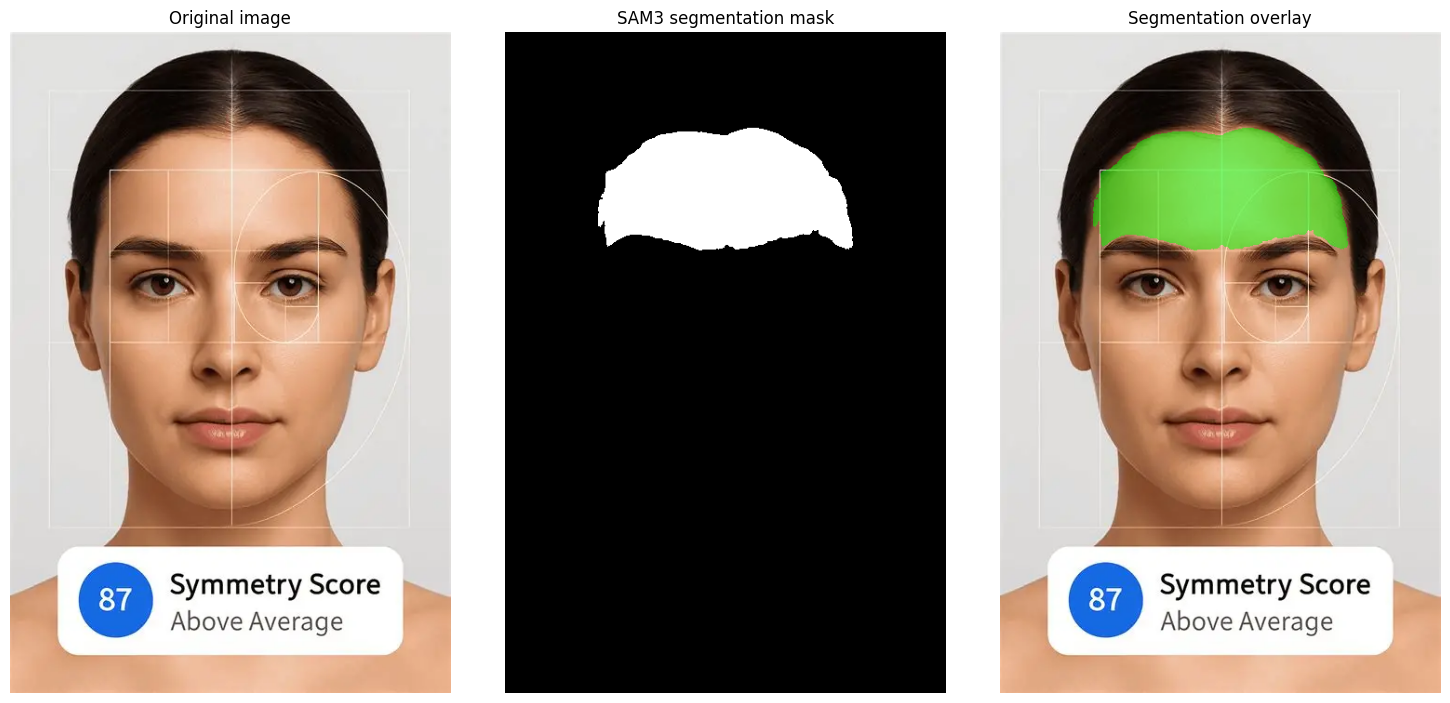

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

image = latest_results["image"]
results = latest_results["results"]

# Move mask from GPU to CPU
mask = results["masks"][0].detach().cpu().numpy().astype(bool)

# Convert original image to NumPy
image_np = np.array(image)

# Create overlay
overlay = image_np.copy()
overlay[mask] = (
    0.5 * image_np[mask] +
    0.5 * np.array([0, 255, 0])
).astype(np.uint8)

# Display original, mask and overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 7))

axes[0].imshow(image_np)
axes[0].set_title("Original image")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("SAM3 segmentation mask")

axes[2].imshow(overlay)
axes[2].set_title("Segmentation overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show( )

In [ ]:

import io
import time
import numpy as np
from PIL import Image
from fastapi import UploadFile, File
from fastapi.responses import Response

# Five facial regions and their overlay colours (RGB)
FACIAL_ZONES = {
    "forehead":   (0, 255, 0),       # Green
    "left cheek": (0, 140, 255),     # Orange
    "right cheek":(255, 80, 180),    # Pink
    "nose":       (255, 220, 0),     # Yellow
    "chin":       (180, 80, 255),    # Purple
}

@app.post("/frame")
async def process_frame(file: UploadFile = File(...)):
    global latest_results

    try:
        contents = await file.read()
        image = Image.open(io.BytesIO(contents)).convert("RGB")
        original = np.array(image)

        overlay = original.copy()
        zone_results = {}

        start_time = time.time()

        # Run SAM3 once for each facial region
        for zone, color in FACIAL_ZONES.items():
            print(f"Segmenting: {zone}")

            results = segment_zone(image, zone)
            zone_results[zone] = results

            if len(results["scores"]) == 0:
                print(f"No detection for {zone}")
                continue

            # Extract the highest-confidence mask
            best_idx = results["scores"].argmax().item()
            mask = (
                results["masks"][best_idx]
                .detach()
                .cpu()
                .numpy()
                .astype(bool)
            )

            # Blend this region into the image
            overlay[mask] = (
                0.5 * overlay[mask].astype(np.float32)
                + 0.5 * np.array(color, dtype=np.float32)
            ).astype(np.uint8)

            print(
                f"{zone}: score = "
                f"{results['scores'][best_idx].item():.3f}"
            )

        elapsed = time.time() - start_time

        latest_results["image"] = image
        latest_results["results"] = zone_results

        # Encode annotated image as JPEG
        output = io.BytesIO()
        Image.fromarray(overlay).save(
            output,
            format="JPEG",
            quality=95
        )

        print(f"All zones processed in {elapsed:.2f}s")

        return Response(
            content=output.getvalue(),
            media_type="image/jpeg"
        )

    except Exception as e:
        print("Processing error:", repr(e))
        raise


# Keep only the newest /frame route
frame_routes = [
    route for route in app.routes
    if getattr(route, "path", None) == "/frame"
    and "POST" in getattr(route, "methods", set())
]

latest_frame_route = frame_routes[-1]

app.routes[:] = [
    route for route in app.routes
    if route not in frame_routes
] + [latest_frame_route]

app.openapi_schema = None

print("Five-zone SAM3 endpoint ready.")
print("Zones:", list(FACIAL_ZONES.keys()))


Five-zone SAM3 endpoint ready.
Zones: ['forehead', 'left cheek', 'right cheek', 'nose', 'chin']


Segmenting: forehead
forehead: score = 0.859
Segmenting: left cheek
No detection for left cheek
Segmenting: right cheek
No detection for right cheek
Segmenting: nose
nose: score = 0.743
Segmenting: chin
chin: score = 0.517
All zones processed in 2.70s
INFO:     31.209.43.212:0 - "POST /frame HTTP/1.1" 200 OK


In [ ]:
FACIAL_ZONES = {
    "forehead": (0, 255, 0),  # Green
    "nose":     (255, 220, 0),  # Yellow
    "chin":     (180, 80, 255),  # Purple
}

print("Active zones:", list(FACIAL_ZONES.keys()))

Active zones: ['forehead', 'nose', 'chin']


Segmenting: forehead
forehead: score = 0.859
Segmenting: nose
nose: score = 0.743
Segmenting: chin
chin: score = 0.517
All zones processed in 1.55s
INFO:     31.209.43.212:0 - "POST /frame HTTP/1.1" 200 OK
